# Ứng dụng Hidden Markov Model (HMM) vào file `NLinh_1.wav`

## Mục tiêu
- Tóm tắt kiến thức **Markov Chain và Hidden Markov Model (HMM)** theo Chương 8 của tài liệu *Spoken Language Processing*.
- Đọc file tiếng nói `NLinh_1.wav`.
- Chia tín hiệu thành các frame ngắn và trích xuất **MFCC + Delta + Delta-Delta** làm vector quan sát.
- Xây dựng **Gaussian HMM** bằng Python/Numpy, không phụ thuộc `hmmlearn`.
- Huấn luyện tham số bằng **Baum-Welch (Forward-Backward)**.
- Dùng **Viterbi** để tìm chuỗi trạng thái ẩn có xác suất cao nhất.
- Trực quan hóa waveform, spectrogram, đặc trưng MFCC và chuỗi trạng thái HMM.

> **Lưu ý:** Với chỉ một file `NLinh_1.wav` và không có nhãn trạng thái/phoneme, bài thực hành này minh họa cách HMM mô hình hóa **cấu trúc biến đổi theo thời gian của một tín hiệu tiếng nói**. Kết quả trạng thái `State 1, State 2, ...` không được tự động hiểu là một âm vị cụ thể.

## 1. Kiến thức cốt lõi về Markov Chain

Theo tài liệu, Markov Chain là mô hình cho một quá trình ngẫu nhiên có **một lượng bộ nhớ tối thiểu**. Với Markov bậc nhất:

$$
P(X_t|X_{t-1},X_{t-2},...,X_1)=P(X_t|X_{t-1})
$$

Nói đơn giản:

> **Trạng thái hiện tại chỉ phụ thuộc vào trạng thái ngay trước đó.**

Nếu có `N` trạng thái, ta dùng:

- **A = [aᵢⱼ]**: ma trận chuyển trạng thái.
- $a_{ij}=P(s_t=j|s_{t-1}=i)$
- **π**: xác suất trạng thái ban đầu.

Mỗi hàng của `A` và `π` phải có tổng bằng 1.

### Ví dụ
Nếu:

$$
A=
\begin{bmatrix}
0.8 & 0.2\\
0.3 & 0.7
\end{bmatrix}
$$

thì khi đang ở State 1, xác suất chuyển sang State 1 là 0.8 và sang State 2 là 0.2.

Markov Chain là **observable**: trạng thái chính là thứ ta quan sát được.

## 2. Từ Markov Chain đến Hidden Markov Model

HMM mở rộng Markov Chain bằng cách tách thành hai lớp:

1. **State (trạng thái ẩn)** `S_t`: không quan sát trực tiếp.
2. **Observation (quan sát)** `X_t`: thứ ta thực sự đo được.

Vì vậy:

$$
S_1 \rightarrow S_2 \rightarrow S_3 \rightarrow ... 
$$

và mỗi trạng thái tạo ra một quan sát:

$$
S_t \rightarrow X_t
$$

Tài liệu định nghĩa HMM bằng bộ tham số:

$$
\Phi=(A,B,\pi)
$$

Trong đó:

- `A`: xác suất chuyển trạng thái.
- `B`: xác suất/phân bố phát sinh quan sát từ trạng thái.
- `π`: phân bố trạng thái ban đầu.

Với HMM rời rạc:

$$
b_i(k)=P(X_t=o_k|S_t=i)
$$

Với tiếng nói, quan sát thường là **vector đặc trưng liên tục**, nên có thể dùng **Continuous HMM**, trong đó `B` là hàm mật độ xác suất; tài liệu trình bày Gaussian mixture density là một lựa chọn cho đầu ra liên tục.

### Hai giả định quan trọng

**Markov assumption**

$$
P(S_t|S_{t-1},...,S_1)=P(S_t|S_{t-1})
$$

**Output-independence assumption**

$$
P(X_t|X_1,...,X_{t-1},S_1,...,S_t)=P(X_t|S_t)
$$

Đây là lý do HMM có thể xử lý chuỗi thời gian mà vẫn giữ số lượng tham số và chi phí tính toán ở mức khả thi.

## 3. Ba bài toán cơ bản của HMM

### Bài toán 1 — Evaluation
Biết HMM `Φ` và chuỗi quan sát `X`, tính:

$$
P(X|\Phi)
$$

Ta dùng **Forward Algorithm**.

Với:

$$
\alpha_t(i)=P(X_1,...,X_t,S_t=i|\Phi)
$$

Công thức:

$$
\alpha_1(i)=\pi_i b_i(X_1)
$$

$$
\alpha_t(j)=b_j(X_t)\sum_i \alpha_{t-1}(i)a_{ij}
$$

Độ phức tạp giảm từ số lượng đường đi tăng theo hàm mũ xuống:

$$
O(N^2T)
$$

---

### Bài toán 2 — Decoding

Biết `X`, tìm chuỗi trạng thái ẩn có xác suất cao nhất:

$$
S^*=\arg\max_S P(S,X|\Phi)
$$

Ta dùng **Viterbi Algorithm**.

Khác với Forward:
- Forward: **cộng** xác suất của mọi đường đi.
- Viterbi: **chọn đường đi tốt nhất** tại mỗi trạng thái và lưu back-pointer để truy vết.

---

### Bài toán 3 — Learning

Có dữ liệu quan sát nhưng chưa biết trạng thái ẩn, cần học:

$$
\Phi=(A,B,\pi)
$$

Tài liệu sử dụng **Baum-Welch / Forward-Backward**, dựa trên tư tưởng EM:

1. Khởi tạo tham số.
2. **E-step:** tính xác suất hậu nghiệm của các trạng thái/chuyển trạng thái bằng Forward + Backward.
3. **M-step:** cập nhật `A`, `B`/các tham số phân bố.
4. Lặp cho đến khi hội tụ.

Với continuous HMM, các tham số của phân bố Gaussian cũng được cập nhật từ các trọng số hậu nghiệm.

## 4. Vì sao HMM phù hợp với tiếng nói?

Tiếng nói là tín hiệu **biến đổi theo thời gian**. Ta không xem toàn bộ file WAV như một điểm dữ liệu duy nhất mà chia thành các frame ngắn.

Ví dụ:

`waveform → frame 1 → frame 2 → frame 3 → ...`

Mỗi frame được biểu diễn bằng một vector đặc trưng.

HMM giả sử:
- mỗi frame được sinh ra bởi một trạng thái ẩn;
- trạng thái hiện tại có liên hệ xác suất với trạng thái trước;
- chuỗi trạng thái mô tả sự tiến triển của tín hiệu theo thời gian.

Tài liệu cũng nêu rằng **left-to-right topology** là cấu trúc tự nhiên cho tiếng nói vì nó mô tả sự tiến triển theo thời gian và có self-transition để biểu diễn đoạn tín hiệu gần như ổn định.

Trong notebook này, để đơn giản và dễ quan sát, ta dùng HMM đầy đủ `N = 5` trạng thái với chuyển tiếp có thể xảy ra giữa mọi trạng thái. Đây là mô hình minh họa, không phải hệ thống nhận dạng phoneme hoàn chỉnh.

In [1]:
# 5. Import thư viện
import os
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
from sklearn.cluster import KMeans
from scipy.special import logsumexp

np.random.seed(42)

AUDIO_PATH = "NLinh_1.wav"

# Nếu notebook được chạy ở thư mục khác, sửa AUDIO_PATH thành đường dẫn tới file WAV.
assert os.path.exists(AUDIO_PATH), f"Không tìm thấy file: {AUDIO_PATH}"

print("Đã sẵn sàng xử lý:", AUDIO_PATH)


Đã sẵn sàng xử lý: NLinh_1.wav


## 6. Đọc file WAV

`librosa.load()` đưa tín hiệu về dạng:

$$
y=[y_1,y_2,...,y_L]
$$

với `sr` là sampling rate.

Ta giữ nguyên sampling rate của file để tránh thay đổi dữ liệu đầu vào.

In [2]:
# Đọc âm thanh
y, sr = librosa.load(AUDIO_PATH, sr=None, mono=True)

duration = len(y) / sr

print(f"Sampling rate : {sr} Hz")
print(f"Số mẫu        : {len(y):,}")
print(f"Thời lượng     : {duration:.2f} giây")
print(f"Biên độ min    : {y.min():.4f}")
print(f"Biên độ max    : {y.max():.4f}")

# Chuẩn hóa nhẹ để thuận tiện khi trực quan hóa
y_plot = y / (np.max(np.abs(y)) + 1e-12)


Sampling rate : 48000 Hz
Số mẫu        : 286,080
Thời lượng     : 5.96 giây
Biên độ min    : -0.2702
Biên độ max    : 0.3271


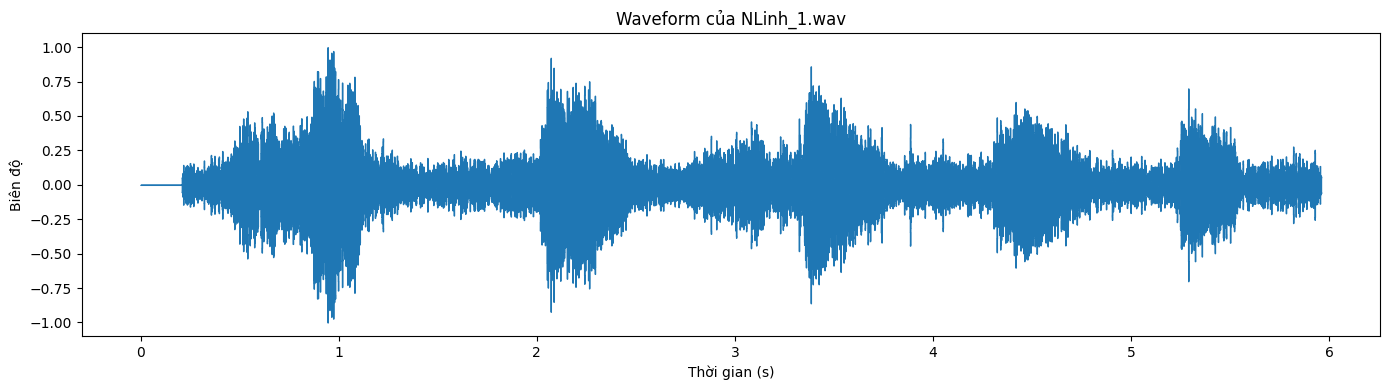

In [3]:
# 7. Nghe và vẽ waveform
from IPython.display import Audio, display

display(Audio(y, rate=sr))

plt.figure(figsize=(14, 4))
librosa.display.waveshow(y_plot, sr=sr)
plt.title("Waveform của NLinh_1.wav")
plt.xlabel("Thời gian (s)")
plt.ylabel("Biên độ")
plt.tight_layout()
plt.show()


## 8. Chuyển tiếng nói thành chuỗi vector quan sát

HMM làm việc với chuỗi:

$$
X=(X_1,X_2,...,X_T)
$$

Trong bài này, mỗi `X_t` là một vector đặc trưng của một frame tiếng nói.

Ta dùng:
- **MFCC 13 chiều**: mô tả đặc trưng phổ theo thang Mel.
- **Delta 13 chiều**: tốc độ thay đổi của MFCC.
- **Delta-Delta 13 chiều**: gia tốc/thay đổi bậc hai.

Tổng cộng:

$$
13+13+13=39
$$

nên mỗi frame trở thành một vector 39 chiều.

Cách này phù hợp với phần continuous HMM của tài liệu: quan sát có thể nằm trong **không gian liên tục** và có thể là vector.

In [4]:
# 8. Trích xuất MFCC + Delta + Delta-Delta
N_MFCC = 13
N_FFT = 1024
HOP_LENGTH = 512

mfcc = librosa.feature.mfcc(
    y=y,
    sr=sr,
    n_mfcc=N_MFCC,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH
)

delta = librosa.feature.delta(mfcc)
delta2 = librosa.feature.delta(mfcc, order=2)

# shape trước khi transpose: (39, số_frame)
features = np.vstack([mfcc, delta, delta2]).T

print("MFCC shape       :", mfcc.shape)
print("Feature shape    :", features.shape)
print("Số frame T       :", features.shape[0])
print("Số chiều vector  :", features.shape[1])


MFCC shape       : (13, 559)
Feature shape    : (559, 39)
Số frame T       : 559
Số chiều vector  : 39


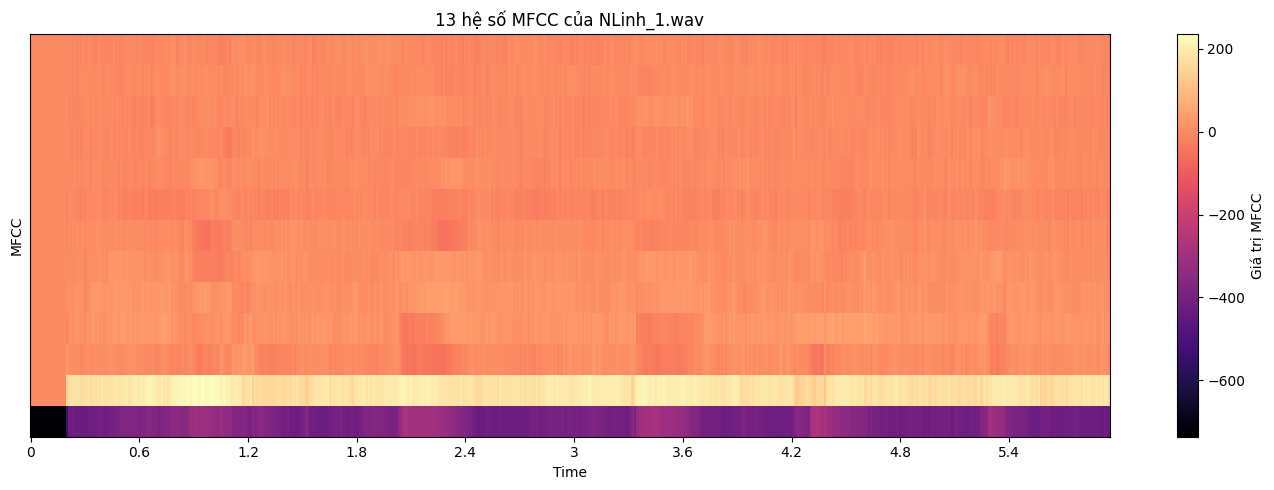

In [5]:
# 9. Trực quan hóa MFCC
plt.figure(figsize=(14, 5))
librosa.display.specshow(
    mfcc,
    x_axis="time",
    sr=sr,
    hop_length=HOP_LENGTH,
    cmap="magma"
)
plt.colorbar(label="Giá trị MFCC")
plt.title("13 hệ số MFCC của NLinh_1.wav")
plt.ylabel("MFCC")
plt.tight_layout()
plt.show()


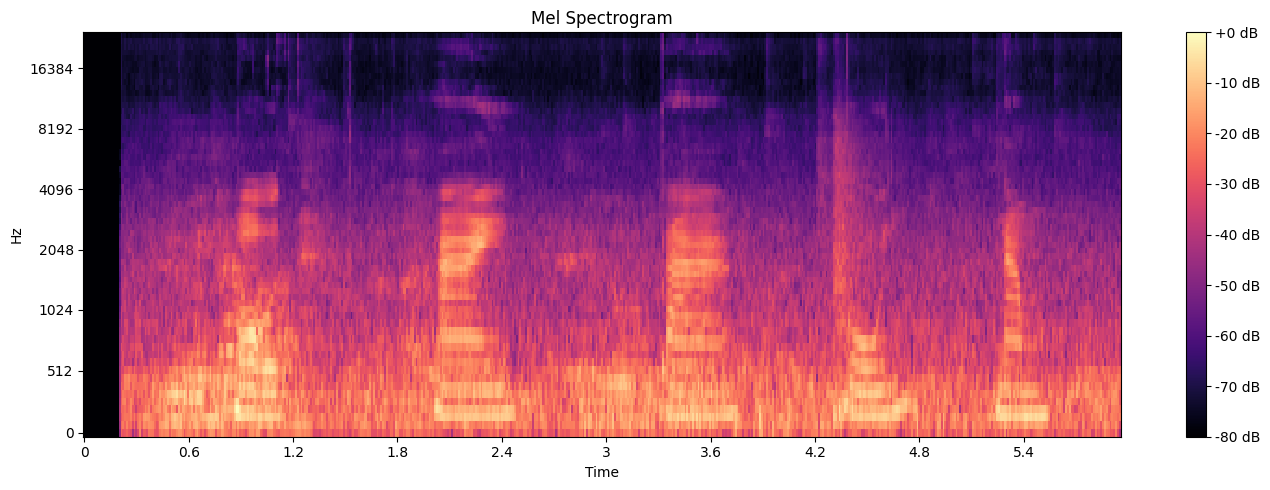

In [6]:
# 10. Spectrogram để quan sát năng lượng theo thời gian
S = librosa.feature.melspectrogram(
    y=y,
    sr=sr,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    n_mels=64
)
S_db = librosa.power_to_db(S, ref=np.max)

plt.figure(figsize=(14, 5))
librosa.display.specshow(
    S_db,
    x_axis="time",
    y_axis="mel",
    sr=sr,
    hop_length=HOP_LENGTH
)
plt.colorbar(format="%+2.0f dB")
plt.title("Mel Spectrogram")
plt.tight_layout()
plt.show()


## 11. Chuẩn hóa vector quan sát

Các chiều MFCC, delta và delta-delta có thang giá trị khác nhau. Ta chuẩn hóa từng chiều:

$$
z=\frac{x-\mu}{\sigma}
$$

Việc này giúp việc ước lượng Gaussian ổn định hơn.

In [7]:
# Chuẩn hóa features theo từng chiều
mu = features.mean(axis=0)
sigma = features.std(axis=0) + 1e-8

X = (features - mu) / sigma

print("X shape:", X.shape)
print("Mean gần 0:", np.mean(X, axis=0)[:5])
print("Std gần 1 :", np.std(X, axis=0)[:5])


X shape: (559, 39)
Mean gần 0: [ 1.9790022e-07  2.6955374e-07 -6.8241452e-09 -7.5065600e-08
 -2.3884509e-08]
Std gần 1 : [0.9999999  1.         1.         1.         0.99999994]


## 12. Gaussian HMM dùng trong bài

Vì `X_t` là vector liên tục, ta dùng **Gaussian emission**:

$$
b_i(X_t)=P(X_t|S_t=i)
$$

Trong notebook, mỗi trạng thái có:
- một vector trung bình `μ_i`;
- một phương sai theo từng chiều `σ²_i`.

Đây là **diagonal-covariance Gaussian HMM**, nghĩa là ta giả sử các chiều đặc trưng có covariance chéo bằng 0 để mô hình đơn giản và ổn định hơn.

Ta chọn:

$$
N=5
$$

trạng thái ẩn.

Để khởi tạo, K-Means chia các frame thành 5 cụm; tâm cụm được dùng làm trung bình ban đầu. Sau đó Baum-Welch tiếp tục học `π`, `A`, `μ`, `σ²`.

In [8]:
# 13. Khởi tạo Gaussian HMM
N_STATES = 5
MAX_ITER = 20
T, D = X.shape

# K-Means chỉ dùng để tạo trạng thái ban đầu hợp lý.
kmeans = KMeans(
    n_clusters=N_STATES,
    random_state=42,
    n_init=10
)
initial_labels = kmeans.fit_predict(X)

means = kmeans.cluster_centers_.copy()
vars_ = np.zeros((N_STATES, D))

for i in range(N_STATES):
    Xi = X[initial_labels == i]
    if len(Xi) > 1:
        vars_[i] = np.var(Xi, axis=0) + 1e-2
    else:
        vars_[i] = np.ones(D)

# Phân bố ban đầu và ma trận chuyển tiếp.
pi = np.bincount(initial_labels, minlength=N_STATES).astype(float)
pi = (pi + 1e-2) / (pi.sum() + N_STATES * 1e-2)

A = np.ones((N_STATES, N_STATES))
for i in range(N_STATES):
    # Có xu hướng ở lại trạng thái hiện tại,
    # phù hợp với bản chất frame liên tiếp của tiếng nói.
    A[i, i] = 4.0
A = A / A.sum(axis=1, keepdims=True)

print("Số trạng thái:", N_STATES)
print("pi =", np.round(pi, 3))
print("A =")
print(np.round(A, 3))


Số trạng thái: 5
pi = [0.118 0.293 0.275 0.277 0.036]
A =
[[0.5   0.125 0.125 0.125 0.125]
 [0.125 0.5   0.125 0.125 0.125]
 [0.125 0.125 0.5   0.125 0.125]
 [0.125 0.125 0.125 0.5   0.125]
 [0.125 0.125 0.125 0.125 0.5  ]]


## 14. Hàm log Gaussian

Do xác suất của nhiều frame khi nhân liên tiếp rất nhỏ, notebook làm việc chủ yếu ở **log-domain**.

Với Gaussian diagonal:

$$
\log b_i(x)=
-\frac12\sum_d
\left[
\log(2\pi\sigma_{id}^2)
+
\frac{(x_d-\mu_{id})^2}{\sigma_{id}^2}
\right]
$$

Dùng log giúp hạn chế hiện tượng underflow khi chuỗi quan sát dài.

In [9]:
def log_gaussian_diag(X, means, vars_):
    """Tính log p(X_t | state_i) cho Gaussian covariance đường chéo."""
    log_det = np.sum(np.log(2 * np.pi * vars_), axis=1)
    diff = X[:, None, :] - means[None, :, :]
    mahal = np.sum((diff ** 2) / vars_[None, :, :], axis=2)
    return -0.5 * (log_det[None, :] + mahal)


def normalize_log_probs(log_values):
    """Chuẩn hóa các log-probability thành probability."""
    log_values = log_values - logsumexp(log_values)
    return np.exp(log_values)


## 15. Forward-Backward

Forward tính:

$$
\alpha_t(j)=P(X_1,...,X_t,S_t=j|\Phi)
$$

Backward tính xác suất của phần quan sát còn lại khi đang ở mỗi state.

Từ hai đại lượng này, ta có xác suất trạng thái tại thời điểm `t`:

$$
\gamma_t(i)=P(S_t=i|X,\Phi)
$$

và xác suất chuyển:

$$
\xi_t(i,j)=P(S_t=i,S_{t+1}=j|X,\Phi)
$$

Đây chính là các đại lượng dùng trong E-step của Baum-Welch.

In [10]:
def forward_log(X, pi, A, means, vars_):
    T = len(X)
    logA = np.log(A + 1e-300)
    logpi = np.log(pi + 1e-300)
    logB = log_gaussian_diag(X, means, vars_)

    alpha = np.empty((T, N_STATES))
    alpha[0] = logpi + logB[0]

    for t in range(1, T):
        for j in range(N_STATES):
            alpha[t, j] = logB[t, j] + logsumexp(
                alpha[t-1] + logA[:, j]
            )

    return alpha, logB


def backward_log(X, A, means, vars_):
    T = len(X)
    logA = np.log(A + 1e-300)
    logB = log_gaussian_diag(X, means, vars_)

    beta = np.zeros((T, N_STATES))

    for t in range(T - 2, -1, -1):
        for i in range(N_STATES):
            beta[t, i] = logsumexp(
                logA[i, :] + logB[t+1, :] + beta[t+1, :]
            )

    return beta


## 16. Huấn luyện Baum-Welch

Mỗi vòng lặp:

**E-step**
- Forward + Backward.
- Tính `gamma` và `xi`.

**M-step**
- Cập nhật `π`.
- Cập nhật `A` bằng tỉ lệ số lần kỳ vọng chuyển `i → j` trên tổng số lần kỳ vọng rời state `i`.
- Cập nhật `μ` và `σ²` bằng trung bình/phương sai có trọng số bởi `gamma`.

Ta theo dõi log-likelihood:

$$
\log P(X|\Phi)
$$

để xem mô hình có cải thiện qua các vòng lặp hay không.

In [11]:
def train_baum_welch(X, pi, A, means, vars_, max_iter=20, tol=1e-4):
    T, D = X.shape
    history = []

    pi = pi.copy()
    A = A.copy()
    means = means.copy()
    vars_ = vars_.copy()

    for iteration in range(max_iter):
        alpha, logB = forward_log(X, pi, A, means, vars_)
        beta = backward_log(X, A, means, vars_)

        loglik = logsumexp(alpha[-1])
        history.append(loglik)

        # gamma[t, i] = P(S_t=i | X)
        log_gamma = alpha + beta
        log_gamma -= logsumexp(log_gamma, axis=1, keepdims=True)
        gamma = np.exp(log_gamma)

        # xi_sum[i,j] = tổng xác suất chuyển i -> j
        xi_sum = np.zeros((N_STATES, N_STATES))

        logA = np.log(A + 1e-300)

        for t in range(T - 1):
            log_xi = (
                alpha[t, :, None]
                + logA
                + logB[t+1, None, :]
                + beta[t+1, None, :]
            )
            log_xi -= logsumexp(log_xi)
            xi_sum += np.exp(log_xi)

        # M-step: pi
        pi = gamma[0]
        pi /= pi.sum()

        # M-step: A
        denom_A = gamma[:-1].sum(axis=0) + 1e-12
        A = xi_sum / denom_A[:, None]
        A = A / A.sum(axis=1, keepdims=True)

        # M-step: Gaussian means / variances
        state_weights = gamma.sum(axis=0) + 1e-12

        means = (gamma.T @ X) / state_weights[:, None]

        for i in range(N_STATES):
            diff = X - means[i]
            vars_[i] = (
                (gamma[:, i, None] * (diff ** 2)).sum(axis=0)
                / state_weights[i]
            ) + 1e-3

        print(f"Iteration {iteration+1:02d}: log-likelihood = {loglik:.4f}")

        if len(history) > 1 and abs(history[-1] - history[-2]) < tol:
            print("Hội tụ.")
            break

    return pi, A, means, vars_, history, gamma


pi, A, means, vars_, history, gamma = train_baum_welch(
    X, pi, A, means, vars_, max_iter=MAX_ITER
)

print("\nπ sau huấn luyện:")
print(np.round(pi, 4))

print("\nA sau huấn luyện:")
print(np.round(A, 4))


Iteration 01: log-likelihood = -27147.8855
Iteration 02: log-likelihood = -26377.7985
Iteration 03: log-likelihood = -25877.7626
Iteration 04: log-likelihood = -25704.2454
Iteration 05: log-likelihood = -25607.0029
Iteration 06: log-likelihood = -25551.1767
Iteration 07: log-likelihood = -25523.7729
Iteration 08: log-likelihood = -25503.1551
Iteration 09: log-likelihood = -25473.6744
Iteration 10: log-likelihood = -25454.3758
Iteration 11: log-likelihood = -25420.2055
Iteration 12: log-likelihood = -25389.3387
Iteration 13: log-likelihood = -25371.9952
Iteration 14: log-likelihood = -25363.3620
Iteration 15: log-likelihood = -25350.0253
Iteration 16: log-likelihood = -25349.8657
Iteration 17: log-likelihood = -25349.8222
Iteration 18: log-likelihood = -25349.8008
Iteration 19: log-likelihood = -25349.7877
Iteration 20: log-likelihood = -25349.7787

π sau huấn luyện:
[0. 0. 0. 0. 1.]

A sau huấn luyện:
[[9.513e-01 3.900e-02 9.800e-03 0.000e+00 0.000e+00]
 [0.000e+00 7.623e-01 5.060e-02 

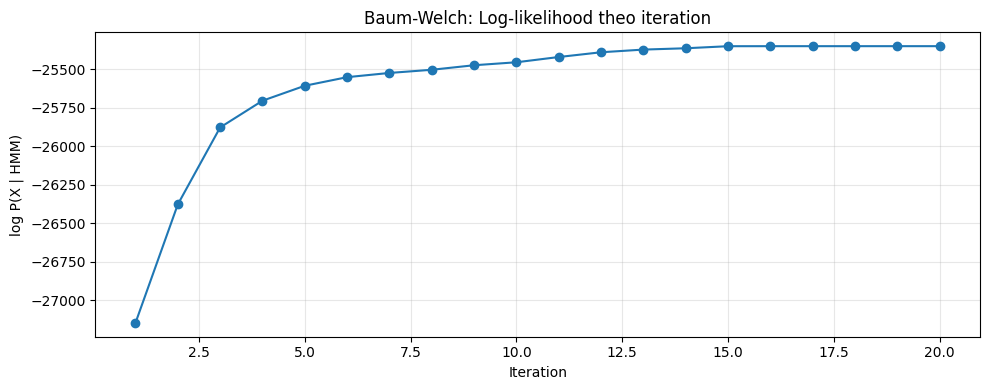

In [12]:
# 17. Kiểm tra quá trình hội tụ
plt.figure(figsize=(10, 4))
plt.plot(range(1, len(history) + 1), history, marker="o")
plt.title("Baum-Welch: Log-likelihood theo iteration")
plt.xlabel("Iteration")
plt.ylabel("log P(X | HMM)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 18. Viterbi — tìm chuỗi trạng thái ẩn

Sau khi HMM đã được huấn luyện, ta muốn biết mỗi frame có khả năng thuộc trạng thái nào.

Viterbi dùng quy hoạch động:

$$
\delta_t(j)=b_j(X_t)\max_i
[\delta_{t-1}(i)a_{ij}]
$$

Sau khi tính xong, ta backtrack để lấy:

$$
S^*=(s_1^*,s_2^*,...,s_T^*)
$$

Chuỗi này là cách HMM phân đoạn tín hiệu thành các trạng thái ẩn.

In [13]:
def viterbi_log(X, pi, A, means, vars_):
    T = len(X)
    logA = np.log(A + 1e-300)
    logpi = np.log(pi + 1e-300)
    logB = log_gaussian_diag(X, means, vars_)

    delta = np.empty((T, N_STATES))
    psi = np.zeros((T, N_STATES), dtype=int)

    delta[0] = logpi + logB[0]

    for t in range(1, T):
        for j in range(N_STATES):
            scores = delta[t-1] + logA[:, j]
            psi[t, j] = np.argmax(scores)
            delta[t, j] = scores[psi[t, j]] + logB[t, j]

    states = np.zeros(T, dtype=int)
    states[-1] = np.argmax(delta[-1])

    for t in range(T - 2, -1, -1):
        states[t] = psi[t+1, states[t+1]]

    return states, delta


states, delta = viterbi_log(X, pi, A, means, vars_)

print("Chuỗi trạng thái Viterbi (20 frame đầu):")
print(states[:20])
print("...")
print("Chuỗi trạng thái Viterbi (20 frame cuối):")
print(states[-20:])
print("\nSố frame:", len(states))


Chuỗi trạng thái Viterbi (20 frame đầu):
[4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 2]
...
Chuỗi trạng thái Viterbi (20 frame cuối):
[3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3]

Số frame: 559


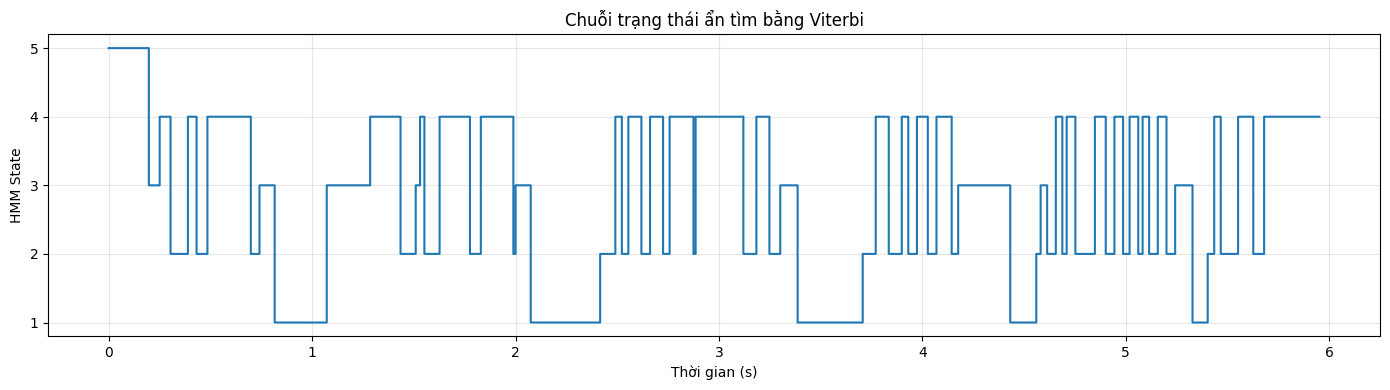

In [14]:
# 19. Trực quan hóa trạng thái HMM theo thời gian
times = librosa.frames_to_time(
    np.arange(T),
    sr=sr,
    hop_length=HOP_LENGTH
)

plt.figure(figsize=(14, 4))
plt.step(times, states + 1, where="mid")
plt.yticks(np.arange(1, N_STATES + 1))
plt.xlabel("Thời gian (s)")
plt.ylabel("HMM State")
plt.title("Chuỗi trạng thái ẩn tìm bằng Viterbi")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 20. Phân đoạn tiếng nói theo trạng thái

Ta có thể nhóm các frame liên tiếp có cùng Viterbi state thành các đoạn.

Điều này minh họa một ưu điểm quan trọng của HMM: **phân đoạn chuỗi dữ liệu biến đổi theo thời gian**. Tài liệu mô tả HMM là một mô hình có thể kết hợp dynamic programming cho pattern segmentation và pattern classification.

In [15]:
# 20. Tạo các đoạn liên tiếp có cùng trạng thái
segments = []
start = 0

for t in range(1, T + 1):
    if t == T or states[t] != states[start]:
        start_time = times[start]
        end_time = (
            times[t - 1] + HOP_LENGTH / sr
        )
        segments.append({
            "state": int(states[start] + 1),
            "start": float(start_time),
            "end": float(end_time),
            "duration": float(end_time - start_time)
        })
        start = t

print("Các đoạn trạng thái:")
for seg in segments:
    print(
        f"State {seg['state']}: "
        f"{seg['start']:.2f}s → {seg['end']:.2f}s "
        f"({seg['duration']:.2f}s)"
    )


Các đoạn trạng thái:
State 5: 0.00s → 0.20s (0.20s)
State 3: 0.20s → 0.26s (0.05s)
State 4: 0.26s → 0.31s (0.05s)
State 2: 0.31s → 0.39s (0.09s)
State 4: 0.39s → 0.44s (0.04s)
State 2: 0.44s → 0.49s (0.05s)
State 4: 0.49s → 0.70s (0.21s)
State 2: 0.70s → 0.75s (0.04s)
State 3: 0.75s → 0.82s (0.07s)
State 1: 0.82s → 1.08s (0.26s)
State 3: 1.08s → 1.29s (0.21s)
State 4: 1.29s → 1.44s (0.15s)
State 2: 1.44s → 1.51s (0.07s)
State 3: 1.51s → 1.54s (0.02s)
State 4: 1.54s → 1.56s (0.02s)
State 2: 1.56s → 1.63s (0.07s)
State 4: 1.63s → 1.78s (0.15s)
State 2: 1.78s → 1.83s (0.05s)
State 4: 1.83s → 1.99s (0.16s)
State 2: 1.99s → 2.01s (0.01s)
State 3: 2.01s → 2.08s (0.07s)
State 1: 2.08s → 2.42s (0.34s)
State 2: 2.42s → 2.50s (0.07s)
State 4: 2.50s → 2.53s (0.03s)
State 2: 2.53s → 2.56s (0.03s)
State 4: 2.56s → 2.62s (0.06s)
State 2: 2.62s → 2.67s (0.04s)
State 4: 2.67s → 2.73s (0.06s)
State 2: 2.73s → 2.76s (0.03s)
State 4: 2.76s → 2.88s (0.12s)
State 2: 2.88s → 2.89s (0.01s)
State 4: 2.89s → 3

## 21. Quan sát nào đặc trưng cho từng trạng thái?

Ta xem số frame Viterbi được gán vào mỗi state. Đây chỉ là mô tả của mô hình trên file hiện tại, **không nên diễn giải State 1 = âm / State 2 = phụ âm...** nếu không có dữ liệu gán nhãn tương ứng.

State 1: 105 frames ( 18.8%)
State 2: 139 frames ( 24.9%)
State 3:  84 frames ( 15.0%)
State 4: 212 frames ( 37.9%)
State 5:  19 frames (  3.4%)


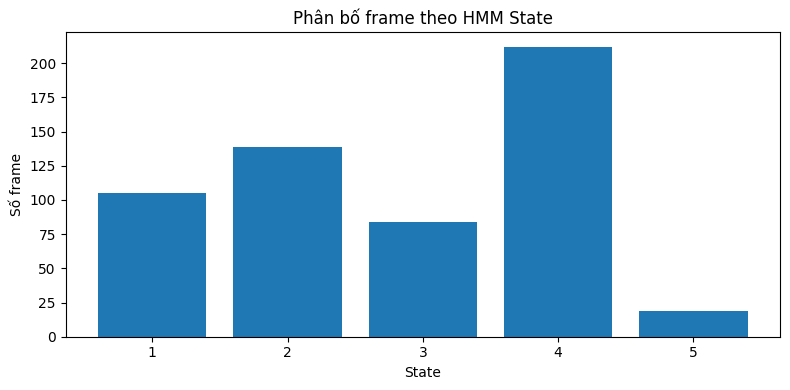

In [16]:
# 21. Thống kê số frame mỗi trạng thái
counts = np.bincount(states, minlength=N_STATES)

for i, count in enumerate(counts, start=1):
    print(
        f"State {i}: {count:3d} frames "
        f"({100*count/T:5.1f}%)"
    )

plt.figure(figsize=(8, 4))
plt.bar(np.arange(1, N_STATES + 1), counts)
plt.xticks(np.arange(1, N_STATES + 1))
plt.xlabel("State")
plt.ylabel("Số frame")
plt.title("Phân bố frame theo HMM State")
plt.tight_layout()
plt.show()


# 22. Kết luận

### Luồng xử lý hoàn chỉnh

```text
NLinh_1.wav
    ↓
Waveform
    ↓
Chia frame theo thời gian
    ↓
MFCC + Delta + Delta-Delta
    ↓
Chuỗi vector quan sát X1, X2, ..., XT
    ↓
Gaussian HMM
    ├── π : trạng thái ban đầu
    ├── A : xác suất chuyển trạng thái
    └── Gaussian emission : xác suất sinh vector quan sát
    ↓
Baum-Welch / Forward-Backward
    ↓
Học tham số HMM
    ↓
Viterbi
    ↓
Chuỗi trạng thái ẩn
    ↓
Phân đoạn NLinh_1.wav theo các trạng thái
```

### Ý nghĩa kết quả

- `A` cho biết xu hướng chuyển giữa các trạng thái.
- `π` cho biết xác suất bắt đầu ở từng trạng thái.
- `means`, `vars` mô tả phân bố đặc trưng của mỗi trạng thái.
- `history` cho biết quá trình Baum-Welch cải thiện log-likelihood.
- `states` là chuỗi trạng thái ẩn do Viterbi tìm được.
- `segments` cho biết các khoảng thời gian mà mô hình giữ một trạng thái.

### Quan trọng

Notebook này là **thực nghiệm HMM trên một file tiếng nói**, không phải một hệ thống nhận dạng giọng nói hoàn chỉnh. Muốn nhận dạng phoneme/từ hoặc phân biệt nhiều người nói cần nhiều file huấn luyện, nhãn phù hợp và thiết kế HMM cho từng lớp/đơn vị cần nhận dạng.

Theo tài liệu, HMM được sử dụng rộng rãi trong speech processing; với quan sát liên tục, continuous HMM thay phân bố output rời rạc bằng hàm mật độ xác suất liên tục.